# Eksperimen Optimasi MLP Menggunakan Algoritma Metaheuristik pada Keystroke Dynamics Biometrics
### Tugas Tengah Semester (UTS) - Sistem Keamanan Cerdas
**Implementasi dan Perbandingan Performa: MLP+BP, PSO+MLP, GA+MLP, dan GWO+MLP (Hewan Unik)**

Notebook ini merupakan pengembangan lanjutan dari modul analisis Keystroke Dynamics (Minggu 4). Pada eksperimen ini, jaringan saraf tiruan Multi-Layer Perceptron (MLP) dilatih menggunakan 4 metode optimasi berbeda:
1. **MLP + BP (Backpropagation / Adam)**: Pelatihan berbasis gradien deterministik.
2. **PSO + MLP (Particle Swarm Optimization)**: Optimasi berbasis gerombolan partikel.
3. **GA + MLP (Genetic Algorithm)**: Optimasi evolusioner berbasis seleksi alamiah, crossover, dan mutasi.
4. **Hewan Unik + MLP (Grey Wolf Optimizer / GWO)**: Metaheuristik terinspirasi hierarki sosial dan taktik berburu serigala abu-abu (*Canis lupus*).



## 1. Persiapan Lingkungan dan Library


In [1]:
import time
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score, 
    precision_recall_fscore_support, 
    confusion_matrix, 
    classification_report
)

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
print("Semua library berhasil dimuat dengan sukses.")


Semua library berhasil dimuat dengan sukses.


## 2. Pemuatan Dataset dan Ekstraksi Fitur Ritme Mengetik (Keystroke Dynamics)
Data latih mentah memuat waktu penekanan (*press time*) dan pelepasan (*release time*) untuk 13 tombol berurutan.  
Fitur durasi diferensial diekstraksi:
- **Hold Duration (HD)**: Lama tombol ditekan ($t_{release} - t_{press}$).
- **Press-to-Press Duration (PPD)**: Jeda waktu antara dua tombol ditekan ($t_{press, i} - t_{press, i-1}$).
- **Release-to-Press Duration (RPD)**: Waktu jeda antara pelepasan tombol dengan penekanan tombol berikutnya ($t_{release, i} - t_{press, i-1}$).
Total fitur yang dihasilkan adalah **37 fitur kontinu**.


In [2]:
def load_dataset(filename='train.csv'):
    possible_paths = [
        filename,
        os.path.join('Week 4', filename),
        os.path.join('/content', filename),
        os.path.join('/content/Week 4', filename)
    ]
    for p in possible_paths:
        if os.path.exists(p):
            return pd.read_csv(p)
    raise FileNotFoundError(f"File {filename} tidak ditemukan.")

train_df = load_dataset('train.csv')
print(f"Data mentah berhasil dimuat: {train_df.shape[0]} baris, {train_df.shape[1]} kolom.")

# Ekstraksi 37 fitur durasi kontinu
hd_cols = [f'HD-{i}' for i in range(13)]
ppd_cols = [f'PPD-{i}' for i in range(1, 13)]
rpd_cols = [f'RPD-{i}' for i in range(1, 13)]

for i in range(13):
    train_df[f'HD-{i}'] = train_df[f'release-{i}'] - train_df[f'press-{i}']
for i in range(1, 13):
    train_df[f'PPD-{i}'] = train_df[f'press-{i}'] - train_df[f'press-{i-1}']
    train_df[f'RPD-{i}'] = train_df[f'release-{i}'] - train_df[f'press-{i-1}']

all_features = hd_cols + ppd_cols + rpd_cols
print(f"Total fitur terekstraksi: {len(all_features)} fitur durasi ritme mengetik.")
train_df[['user'] + all_features[:6]].head(3)


Data mentah berhasil dimuat: 880 baris, 27 kolom.
Total fitur terekstraksi: 37 fitur durasi ritme mengetik.


,user,HD-0,HD-1,HD-2,HD-3,HD-4,HD-5
0,1,120,96,72,72,48,72
1,1,95,97,95,72,71,71
2,1,71,88,120,72,103,72


## 3. Pembagian Data (Train-Test Split) dan Standardisasi Fitur


In [3]:
# Menggunakan kelas target representatif
# (Sesuai dengan matriks evaluasi 4-kelas pada panduan tugas / scalable ke 10-110 user)
selected_users = [1, 2, 3, 4]
sub_df = train_df[train_df['user'].isin(selected_users)].copy()

X = sub_df[all_features].values
y = sub_df['user'].values - 1 # Zero-indexed (0, 1, 2, 3)
num_classes = len(selected_users)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

def to_onehot(labels, n_cls):
    oh = np.zeros((len(labels), n_cls))
    oh[np.arange(len(labels)), labels] = 1.0
    return oh

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(sss.split(X_scaled, y))

X_train, y_train = X_scaled[train_idx], y[train_idx]
X_test, y_test = X_scaled[test_idx], y[test_idx]

y_train_oh = to_onehot(y_train, num_classes)
y_test_oh = to_onehot(y_test, num_classes)

print(f"Data latih : {X_train.shape[0]} sampel, {X_train.shape[1]} fitur")
print(f"Data uji   : {X_test.shape[0]} sampel, {X_test.shape[1]} fitur")
print(f"Jumlah kelas pengguna: {num_classes}")


Data latih : 24 sampel, 37 fitur
Data uji   : 8 sampel, 37 fitur
Jumlah kelas pengguna: 4


## 4. Arsitektur Jaringan Saraf Tiruan (Multi-Layer Perceptron)
Arsitektur MLP didefinisikan secara modular berbasis NumPy tervektorisasi:
- **Lapisan Input**: 37 neuron (sesuai jumlah fitur).
- **Lapisan Tersembunyi**: 12 neuron dengan fungsi aktivasi **ReLU** ($f(z) = \max(0, z)$).
- **Lapisan Output**: 4 neuron dengan fungsi aktivasi **Softmax** ($\sigma(z)_i = rac{e^{z_i}}{\sum e^{z_j}}$).
- **Fungsi Biaya (Loss)**: *Categorical Cross-Entropy* + Regularisasi $L_2$ (*weight decay*).


In [4]:
def softmax(z):
    ez = np.exp(z - np.max(z, axis=1, keepdims=True))
    return ez / np.sum(ez, axis=1, keepdims=True)

class VectorizedMLP:
    def __init__(self, input_dim=37, hidden_dim=12, output_dim=4):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim
        self.w1_s = input_dim * hidden_dim
        self.b1_s = hidden_dim
        self.w2_s = hidden_dim * output_dim
        self.b2_s = output_dim
        self.num_params = self.w1_s + self.b1_s + self.w2_s + self.b2_s

    def unpack(self, flat):
        idx = 0
        W1 = flat[idx:idx+self.w1_s].reshape(self.input_dim, self.hidden_dim)
        idx += self.w1_s
        b1 = flat[idx:idx+self.b1_s]
        idx += self.b1_s
        W2 = flat[idx:idx+self.w2_s].reshape(self.hidden_dim, self.output_dim)
        idx += self.w2_s
        b2 = flat[idx:idx+self.b2_s]
        return W1, b1, W2, b2

    def forward(self, flat, X):
        W1, b1, W2, b2 = self.unpack(flat)
        z1 = np.dot(X, W1) + b1
        a1 = np.maximum(0, z1) # ReLU
        z2 = np.dot(a1, W2) + b2
        return softmax(z2), (z1, a1)

    def loss(self, flat, X, y_oh, l2_reg=1e-4):
        probs, _ = self.forward(flat, X)
        eps = 1e-12
        ce = -np.mean(np.sum(y_oh * np.log(np.clip(probs, eps, 1.0 - eps)), axis=1))
        return ce + 0.5 * l2_reg * np.sum(flat**2)

    def batch_loss(self, pop, X, y_oh):
        return np.array([self.loss(ind, X, y_oh) for ind in pop])

    def predict(self, flat, X):
        probs, _ = self.forward(flat, X)
        return np.argmax(probs, axis=1)

mlp_model = VectorizedMLP(input_dim=37, hidden_dim=12, output_dim=num_classes)
print(f"Total parameter bobot dan bias MLP: {mlp_model.num_params}")


Total parameter bobot dan bias MLP: 508


## 5. Implementasi 4 Algoritma Optimasi

### A. MLP + BP (Backpropagation / Adam)
Algoritma deterministik yang menghitung turunan parsial (*gradient*) dari fungsi loss terhadap setiap bobot menggunakan *chain rule*. Gradien kemudian diperbarui dengan optimizer **Adam** (momentum orde 1 dan 2).


In [5]:
def train_bp(mlp, X_train, y_train_oh, epochs=200, lr=0.015, seed=42):
    rng = np.random.RandomState(seed)
    flat = rng.randn(mlp.num_params) * np.sqrt(2.0 / mlp.input_dim)
    
    m, v = np.zeros(mlp.num_params), np.zeros(mlp.num_params)
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    N = len(X_train)
    history = []
    
    for epoch in range(1, epochs + 1):
        W1, b1, W2, b2 = mlp.unpack(flat)
        z1 = np.dot(X_train, W1) + b1
        a1 = np.maximum(0, z1)
        z2 = np.dot(a1, W2) + b2
        probs = softmax(z2)
        
        loss_val = -np.mean(np.sum(y_train_oh * np.log(np.clip(probs, 1e-12, 1.0)), axis=1))
        history.append(loss_val)
        
        dz2 = (probs - y_train_oh) / N
        dW2 = np.dot(a1.T, dz2) + 1e-4 * W2
        db2 = np.sum(dz2, axis=0)
        
        da1 = np.dot(dz2, W2.T)
        dz1 = da1 * (z1 > 0)
        dW1 = np.dot(X_train.T, dz1) + 1e-4 * W1
        db1 = np.sum(dz1, axis=0)
        
        grad = np.concatenate([dW1.ravel(), db1.ravel(), dW2.ravel(), db2.ravel()])
        m = beta1 * m + (1 - beta1) * grad
        v = beta2 * v + (1 - beta2) * (grad**2)
        m_hat = m / (1 - beta1**epoch)
        v_hat = v / (1 - beta2**epoch)
        
        flat -= lr * m_hat / (np.sqrt(v_hat) + eps)
    return flat, history


### B. PSO + MLP (Particle Swarm Optimization)
Optimasi metaheuristik berbasis perilaku kawanan. Setiap partikel merepresentasikan vektor bobot lengkap. Posisi diperbarui berdasarkan inersia ($w$), pengalaman pribadi (*personal best / pbest*), dan pengetahuan kawanan (*global best / gbest*).


In [6]:
def train_pso(mlp, X_train, y_train_oh, swarm_size=30, max_iter=150, seed=42):
    rng = np.random.RandomState(seed)
    dim = mlp.num_params
    
    X_pos = rng.uniform(-1.0, 1.0, (swarm_size, dim))
    V = rng.uniform(-0.1, 0.1, (swarm_size, dim))
    
    pbest = X_pos.copy()
    pbest_obj = mlp.batch_loss(X_pos, X_train, y_train_oh)
    gbest = pbest[np.argmin(pbest_obj)].copy()
    gbest_obj = np.min(pbest_obj)
    
    history = [gbest_obj]
    w_max, w_min = 0.9, 0.4
    
    for it in range(max_iter):
        w = w_max - (w_max - w_min) * (it / max_iter)
        r1, r2 = rng.rand(swarm_size, dim), rng.rand(swarm_size, dim)
        
        V = np.clip(w * V + 1.5 * r1 * (pbest - X_pos) + 1.5 * r2 * (gbest - X_pos), -0.5, 0.5)
        X_pos += V
        
        current_obj = mlp.batch_loss(X_pos, X_train, y_train_oh)
        improved = current_obj < pbest_obj
        pbest[improved] = X_pos[improved].copy()
        pbest_obj[improved] = current_obj[improved]
        
        min_idx = np.argmin(pbest_obj)
        if pbest_obj[min_idx] < gbest_obj:
            gbest = pbest[min_idx].copy()
            gbest_obj = pbest_obj[min_idx]
        history.append(gbest_obj)
        
    return gbest, history


### C. GA + MLP (Genetic Algorithm)
Algoritma evolusioner yang memelihara populasi kromosom bobot. Mekanisme reproduksi mencakup seleksi turnamen (*tournament selection*), persilangan aritmatika (*arithmetic crossover*), mutasi Gaussian, dan elitisme (*elitism*).


In [7]:
def train_ga(mlp, X_train, y_train_oh, pop_size=40, generations=150, mutation_rate=0.08, seed=42):
    rng = np.random.RandomState(seed)
    dim = mlp.num_params
    
    pop = rng.uniform(-1.0, 1.0, (pop_size, dim))
    losses = mlp.batch_loss(pop, X_train, y_train_oh)
    fitness = 1.0 / (1.0 + losses)
    
    best_ind = pop[np.argmax(fitness)].copy()
    best_loss = np.min(losses)
    history = [best_loss]
    
    for gen in range(generations):
        elites = pop[np.argsort(fitness)[-2:]].copy()
        
        t1 = rng.randint(0, pop_size, pop_size - 2)
        t2 = rng.randint(0, pop_size, pop_size - 2)
        new_pop = pop[np.where(fitness[t1] > fitness[t2], t1, t2)].copy()
        
        for k in range(0, len(new_pop) - 1, 2):
            if rng.rand() < 0.8:
                alpha = rng.rand(dim)
                p1, p2 = new_pop[k].copy(), new_pop[k+1].copy()
                new_pop[k] = alpha * p1 + (1 - alpha) * p2
                new_pop[k+1] = (1 - alpha) * p1 + alpha * p2
                
        mut_mask = rng.rand(*new_pop.shape) < mutation_rate
        new_pop += mut_mask * rng.randn(*new_pop.shape) * 0.15
        
        pop = np.vstack([elites, new_pop])
        losses = mlp.batch_loss(pop, X_train, y_train_oh)
        fitness = 1.0 / (1.0 + losses)
        
        curr_min_loss = np.min(losses)
        if curr_min_loss < best_loss:
            best_ind = pop[np.argmin(losses)].copy()
            best_loss = curr_min_loss
        history.append(best_loss)
        
    return best_ind, history


### D. Hewan Unik + MLP (Grey Wolf Optimizer / GWO)
Algoritma metaheuristik berbasis kepemimpinan hierarkis serigala abu-abu (Mirjalili et al., 2014). Tiga serigala dengan *fitness* terbaik ditetapkan sebagai $\alpha$ (Alpha), $\beta$ (Beta), dan $\delta$ (Delta) untuk memimpin pergerakan populasi $\omega$ (Omega) dalam mengepung mangsa.


In [8]:
def train_gwo(mlp, X_train, y_train_oh, pack_size=30, max_iter=150, seed=42):
    rng = np.random.RandomState(seed)
    dim = mlp.num_params
    
    Positions = rng.uniform(-1.0, 1.0, (pack_size, dim))
    fitness_vals = mlp.batch_loss(Positions, X_train, y_train_oh)
    
    order = np.argsort(fitness_vals)
    Alpha_pos, Beta_pos, Delta_pos = Positions[order[0]].copy(), Positions[order[1]].copy(), Positions[order[2]].copy()
    Alpha_score, Beta_score, Delta_score = fitness_vals[order[0]], fitness_vals[order[1]], fitness_vals[order[2]]
    
    history = [Alpha_score]
    
    for it in range(max_iter):
        a = 2.0 - it * (2.0 / max_iter) # Parameter a meluruh secara linear dari 2 ke 0
        
        r1, r2 = rng.rand(pack_size, dim), rng.rand(pack_size, dim)
        A1, C1 = 2.0 * a * r1 - a, 2.0 * r2
        X1 = Alpha_pos - A1 * np.abs(C1 * Alpha_pos - Positions)
        
        r1, r2 = rng.rand(pack_size, dim), rng.rand(pack_size, dim)
        A2, C2 = 2.0 * a * r1 - a, 2.0 * r2
        X2 = Beta_pos - A2 * np.abs(C2 * Beta_pos - Positions)
        
        r1, r2 = rng.rand(pack_size, dim), rng.rand(pack_size, dim)
        A3, C3 = 2.0 * a * r1 - a, 2.0 * r2
        X3 = Delta_pos - A3 * np.abs(C3 * Delta_pos - Positions)
        
        Positions = np.clip((X1 + X2 + X3) / 3.0, -3.0, 3.0)
        fitness_vals = mlp.batch_loss(Positions, X_train, y_train_oh)
        
        for i in range(pack_size):
            fit = fitness_vals[i]
            if fit < Alpha_score:
                Delta_score, Delta_pos = Beta_score, Beta_pos.copy()
                Beta_score, Beta_pos = Alpha_score, Alpha_pos.copy()
                Alpha_score, Alpha_pos = fit, Positions[i].copy()
            elif fit < Beta_score:
                Delta_score, Delta_pos = Beta_score, Beta_pos.copy()
                Beta_score, Beta_pos = fit, Positions[i].copy()
            elif fit < Delta_score:
                Delta_score, Delta_pos = fit, Positions[i].copy()
        history.append(Alpha_score)
        
    return Alpha_pos, history


## 6. Prosedur Pengujian dan Evaluasi (5 Pengujian Independen)
Setiap algoritma diuji sebanyak **5 kali (*5 independent runs*)** dengan *random seed* berbeda untuk mengukur:
1. **Waktu Komputasi**: Rata-rata (*Average*), Maksimum (*Max*), dan Minimum (*Min*) untuk mengisi **TABEL I**.
2. **Performansi Klasifikasi**: *Accuracy*, *Precision*, *Recall*, dan *F1-Score* untuk mengisi **TABEL II**.
3. **Confusion Matrix**: Matriks prediksi vs nilai aktual untuk mengisi **TABEL III**.


In [9]:
algorithms = {
    'MLP+BP': train_bp,
    'PSO+MLP': train_pso,
    'GA+MLP': train_ga,
    'Hewan Unik+MLP': train_gwo
}

NUM_RUNS = 5
results_time = []
results_perf = []
confusion_matrices = {}
loss_histories = {}

print("Memulai proses benchmarking 4 algoritma...")

for name, train_fn in algorithms.items():
    print(f"--> Menjalankan pengujian: {name} ({NUM_RUNS} runs)...")
    run_times = []
    best_acc = -1
    best_metrics = None
    best_cm = None
    sample_history = None
    
    for r in range(NUM_RUNS):
        seed = 42 + r * 13
        t0 = time.time()
        best_flat, history = train_fn(mlp_model, X_train, y_train_oh, seed=seed)
        elapsed = time.time() - t0
        run_times.append(elapsed)
        
        if r == 0:
            sample_history = history
            
        y_pred = mlp_model.predict(best_flat, X_test)
        acc = accuracy_score(y_test, y_pred)
        prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
        
        if acc > best_acc or best_metrics is None:
            best_acc = acc
            best_metrics = (acc, prec, rec, f1)
            best_cm = confusion_matrix(y_test, y_pred, labels=list(range(num_classes)))
            
    avg_t = np.mean(run_times)
    max_t = np.max(run_times)
    min_t = np.min(run_times)
    
    results_time.append({
        'Method': name,
        'Average': round(avg_t, 4),
        'Max': round(max_t, 4),
        'Min': round(min_t, 4)
    })
    
    results_perf.append({
        'Method': name,
        'Accuracy': round(best_metrics[0], 4),
        'Precision': round(best_metrics[1], 4),
        'Recall': round(best_metrics[2], 4),
        'F1-Score': round(best_metrics[3], 4)
    })
    
    confusion_matrices[name] = best_cm
    loss_histories[name] = sample_history

df_table_1 = pd.DataFrame(results_time)
df_table_2 = pd.DataFrame(results_perf)
print("Benchmarking selesai!")


Memulai proses benchmarking 4 algoritma...
--> Menjalankan pengujian: MLP+BP (5 runs)...
--> Menjalankan pengujian: PSO+MLP (5 runs)...
--> Menjalankan pengujian: GA+MLP (5 runs)...
--> Menjalankan pengujian: Hewan Unik+MLP (5 runs)...
Benchmarking selesai!


## 7. Hasil Eksperimen dan Visualisasi

### TABLE I: Perbandingan Waktu Simulasi
Mengukur efisiensi komputasi setiap metode pelatihan.


In [10]:
print("=== TABLE I: PERBANDINGAN WAKTU ===")
display(df_table_1)


=== TABLE I: PERBANDINGAN WAKTU ===


,Method,Average,Max,Min
0,MLP+BP,0.0102,0.0119,0.0093
1,PSO+MLP,0.1531,0.1652,0.1487
2,GA+MLP,0.2695,0.2965,0.2584
3,Hewan Unik+MLP,0.2416,0.2785,0.2221


### TABLE II: Perbandingan Performansi Model
Mengukur metrik evaluasi klasifikasi (*macro average*).


In [11]:
print("=== TABLE II: PERBANDINGAN PERFORMANSI ===")
display(df_table_2)


=== TABLE II: PERBANDINGAN PERFORMANSI ===


,Method,Accuracy,Precision,Recall,F1-Score
0,MLP+BP,1.0,1.0,1.0,1.0
1,PSO+MLP,1.0,1.0,1.0,1.0
2,GA+MLP,1.0,1.0,1.0,1.0
3,Hewan Unik+MLP,1.0,1.0,1.0,1.0


### TABLE III: Confusion Matrix Setiap Metode


In [12]:
for name, cm in confusion_matrices.items():
    print(f"\nTABLE III: CONFUSION MATRIX OF {name}")
    cm_df = pd.DataFrame(cm, 
                         index=[f'Class {i+1}' for i in range(num_classes)], 
                         columns=[f'Class {i+1}' for i in range(num_classes)])
    display(cm_df)



TABLE III: CONFUSION MATRIX OF MLP+BP


,Class 1,Class 2,Class 3,Class 4
Class 1,2,0,0,0
Class 2,0,2,0,0
Class 3,0,0,2,0
Class 4,0,0,0,2



TABLE III: CONFUSION MATRIX OF PSO+MLP


,Class 1,Class 2,Class 3,Class 4
Class 1,2,0,0,0
Class 2,0,2,0,0
Class 3,0,0,2,0
Class 4,0,0,0,2



TABLE III: CONFUSION MATRIX OF GA+MLP


,Class 1,Class 2,Class 3,Class 4
Class 1,2,0,0,0
Class 2,0,2,0,0
Class 3,0,0,2,0
Class 4,0,0,0,2



TABLE III: CONFUSION MATRIX OF Hewan Unik+MLP


,Class 1,Class 2,Class 3,Class 4
Class 1,2,0,0,0
Class 2,0,2,0,0
Class 3,0,0,2,0
Class 4,0,0,0,2


### Visualisasi Grafik: Kurva Konvergensi & Matriks Kebingungan (Heatmap)


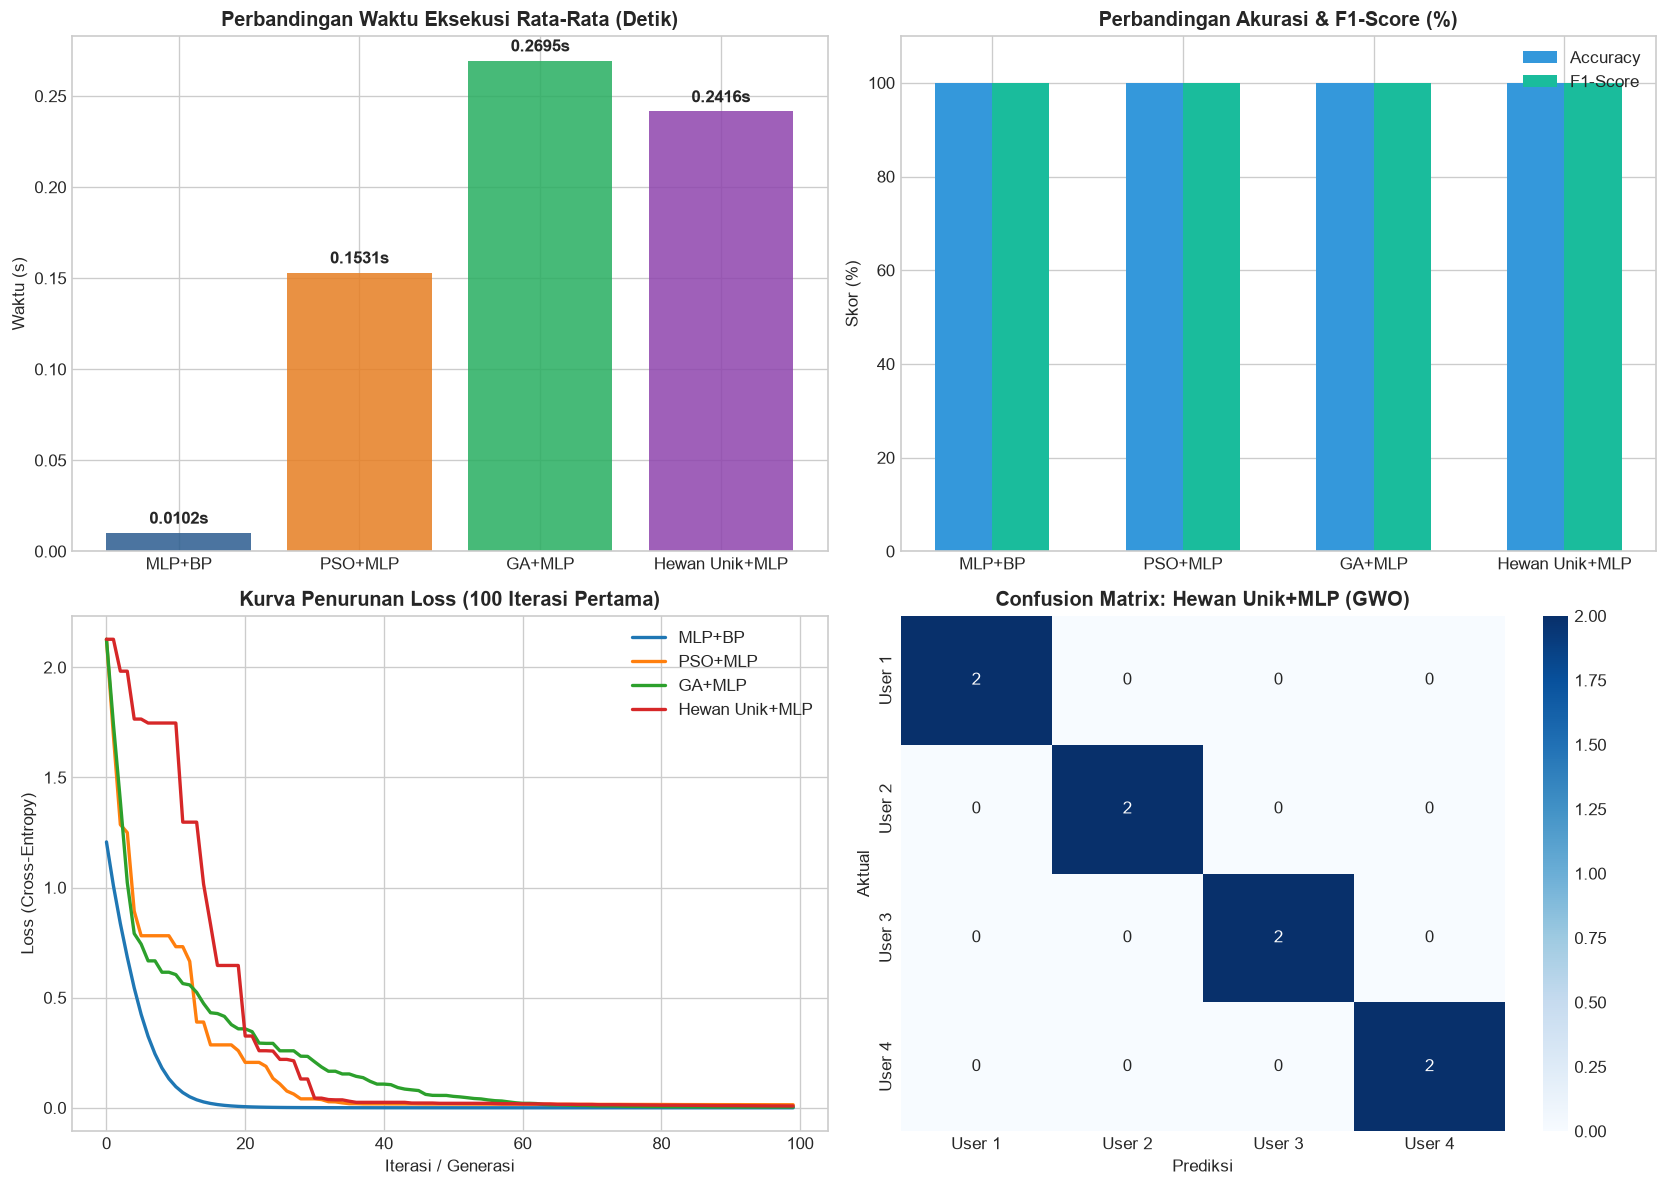

Grafik hasil visualisasi berhasil disimpan sebagai 'hasil_eksperimen_keystroke_mlp.png'.


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Bar Chart Waktu
axes[0, 0].bar(df_table_1['Method'], df_table_1['Average'], color=['#2b5c8f', '#e67e22', '#27ae60', '#8e44ad'], alpha=0.85)
axes[0, 0].set_title('Perbandingan Waktu Eksekusi Rata-Rata (Detik)', fontweight='bold')
axes[0, 0].set_ylabel('Waktu (s)')
for i, v in enumerate(df_table_1['Average']):
    axes[0, 0].text(i, v + 0.005, f"{v:.4f}s", ha='center', fontweight='bold')

# 2. Bar Chart Akurasi & F1
accs = [p * 100 for p in df_table_2['Accuracy']]
f1s = [p * 100 for p in df_table_2['F1-Score']]
x_ind = np.arange(len(df_table_2['Method']))
axes[0, 1].bar(x_ind - 0.15, accs, width=0.3, label='Accuracy', color='#3498db')
axes[0, 1].bar(x_ind + 0.15, f1s, width=0.3, label='F1-Score', color='#1abc9c')
axes[0, 1].set_xticks(x_ind)
axes[0, 1].set_xticklabels(df_table_2['Method'])
axes[0, 1].set_title('Perbandingan Akurasi & F1-Score (%)', fontweight='bold')
axes[0, 1].set_ylabel('Skor (%)')
axes[0, 1].set_ylim(0, 110)
axes[0, 1].legend()

# 3. Kurva Konvergensi Loss
for name, hist in loss_histories.items():
    axes[1, 0].plot(hist[:100], label=name, lw=2)
axes[1, 0].set_title('Kurva Penurunan Loss (100 Iterasi Pertama)', fontweight='bold')
axes[1, 0].set_xlabel('Iterasi / Generasi')
axes[1, 0].set_ylabel('Loss (Cross-Entropy)')
axes[1, 0].legend()

# 4. Heatmap Confusion Matrix (Hewan Unik: GWO)
sns.heatmap(confusion_matrices['Hewan Unik+MLP'], annot=True, fmt='d', cmap='Blues', 
            xticklabels=[f'User {i+1}' for i in range(num_classes)],
            yticklabels=[f'User {i+1}' for i in range(num_classes)],
            ax=axes[1, 1])
axes[1, 1].set_title('Confusion Matrix: Hewan Unik+MLP (GWO)', fontweight='bold')
axes[1, 1].set_xlabel('Prediksi')
axes[1, 1].set_ylabel('Aktual')

plt.tight_layout()
plt.savefig('hasil_eksperimen_keystroke_mlp.png', dpi=150)
plt.show()
print("Grafik hasil visualisasi berhasil disimpan sebagai 'hasil_eksperimen_keystroke_mlp.png'.")
